# FitNets KD Student — SSL-CL-DNN Teacher

Notebook train **1 student** bằng **FitNets** (Romero et al., ICLR 2015) — *huấn luyện 2 giai đoạn* đúng theo paper:

**Giai đoạn 1 — Hint-based Training (Eq. 3):**
$$\mathcal{L}_{HT}(W_{Guided}, W_r) = \tfrac{1}{2}\,\bigl\| u_h(x; W_{Hint}) - r\bigl(v_g(x; W_{Guided}); W_r\bigr) \bigr\|^2$$
Train student từ đầu tới **guided layer** + regressor để khớp **hint layer** của teacher.

**Giai đoạn 2 — Knowledge Distillation (Eq. 2):**
$$\mathcal{L}_{KD}(W_S) = \mathcal{H}(y_{true}, P_S) + \lambda\,\mathcal{H}(P_T^{\tau}, P_S^{\tau})$$
Train **toàn bộ** student, khởi tạo từ tham số của giai đoạn 1.

| Thành phần | Chọn (bám paper "middle layer") |
|---|---|
| Hint (teacher) | output khối giữa của `DNNEncoder` → **512-dim** |
| Guided (student) | output khối giữa của `MiniDNNEncoder` → **64-dim** |
| Regressor | `Linear(64 → 512)` + ReLU (khớp non-linearity của hint) |

Kiến trúc student, teacher, dataset, LR, batch size **giữ nguyên** từ notebook `3-student-ssl-cl-dnn`. λ giảm tuyến tính 4→1, τ=3 theo paper.

**Ngân sách epoch:** hint 50 + KD 50 = 100 epoch tổng. Giai đoạn KD để **50 epoch ngang bằng v1/v2/v3** nhằm so sánh công bằng; giai đoạn hint tính là chi phí khởi tạo (tương tự pre-training), không trừ vào ngân sách KD. Paper gốc dùng early stopping độc lập cho từng giai đoạn nên không quy định tỉ lệ cố định.


## Cell 1 — Cấu hình & Import

In [1]:
!pip install -q pyarrow pandas scikit-learn torch matplotlib seaborn

import os, gc, time, glob, warnings, json, tracemalloc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from sklearn.metrics import (
    classification_report, roc_auc_score,
    accuracy_score, confusion_matrix, f1_score
)

warnings.filterwarnings('ignore')

# ── Đường dẫn (giữ nguyên từ notebook gốc) ───────────────────────────────────
INPUT_DIR    = '/kaggle/input/datasets/rsnngo/37ft-thang3737'
TEACHER_PTH  = '/kaggle/input/datasets/rsnngo/teacher-model-thang3737/teacher_ssl_cl_dnn_after_optuna_37ft.pth'
OUTPUT_DIR   = '/kaggle/working/'
TRAIN_FILE   = os.path.join(INPUT_DIR, 'train_standard_p3.2.parquet')
VAL_FILE     = os.path.join(INPUT_DIR, 'val_standard_p3.2.parquet')
TEST_FILE    = os.path.join(INPUT_DIR, 'test_standard_p3.2.parquet')
CLASS_WEIGHTS_JSON = os.path.join(INPUT_DIR, 'class_weights_p3.2.json')

# Output cho FitNets
FITNET_PATH  = os.path.join(OUTPUT_DIR, 'student_ssl_cl_dnn_fitnets_37ft.pth')
FITNET_CKPT_DIR = os.path.join(OUTPUT_DIR, 'ckpt_fitnets')
for d in [OUTPUT_DIR, FITNET_CKPT_DIR]:
    os.makedirs(d, exist_ok=True)

# ── Hằng số model (giữ nguyên) ───────────────────────────────────────────────
NUM_FEATURES      = 37
NUM_CLASSES       = 8
LABEL_COL         = 'label'
TEACHER_EMBED_DIM = 256
STUDENT_EMBED_DIM = 64
LABEL_NAMES = {0:'Benign',1:'DDoS',2:'DoS',3:'BruteForce',
               4:'Spoofing',5:'Recon',6:'Web-Based',7:'Mirai'}
CLASS_NAMES = [LABEL_NAMES[i] for i in range(NUM_CLASSES)]
COLORS = ['#4C9BE8','#E84C4C','#F5A623','#9B59B6',
          '#2ECC71','#1ABC9C','#8B4513','#607D8B']

# ── Hyperparameters training (LR & batch lấy trực tiếp từ Cell 1 gốc) ─────────
BATCH_SIZE       = 128
LR               = 0.0001487
#  lr                = 0.0001487
#  batch_size        = 128 tu optuna sslcldnn 37ft
WEIGHT_DECAY     = 0.01
CLASS_WEIGHT_MAX = 3.0        # clip max cho class weight
CHECKPOINT_EVERY = 5
RANDOM_SEED      = 42

# ── FitNets hyperparams (theo paper Romero et al. 2015) ──────────────────────
# Hai giai đoạn ĐỘC LẬP, mỗi giai đoạn 50 epoch.
# KD = 50 epoch để NGANG BẰNG với v1/v2/v3 (so sánh công bằng).
# Hint = 50 epoch, coi như chi phí khởi tạo (tương tự pre-training), không tính vào ngân sách KD.
HINT_EPOCHS      = 50          # giai đoạn 1: hint-based pre-training
KD_EPOCHS        = 50         # giai đoạn 2: KD
N_EPOCHS         = HINT_EPOCHS + KD_EPOCHS   # tổng = 100

# Hint/guided layer indices (middle layer, theo paper)
# Teacher DNNEncoder: [Lin46->512, ReLU, Lin512->512, ReLU, Lin512->256, ReLU, Lin256->256, ReLU]
#   hint = sau block giữa (index 3 = ReLU sau Linear(512,512)) -> 512-dim
# Student MiniDNNEncoder: [Lin46->128, ReLU, Lin128->64, ReLU, Lin64->64, ReLU]
#   guided = sau block giữa (index 3 = ReLU sau Linear(128,64)) -> 64-dim
TEACHER_HINT_IDX = 3          # output index trong nn.Sequential teacher encoder
STUDENT_GUIDED_IDX = 3        # output index trong nn.Sequential student encoder
HINT_DIM   = 512              # chiều hint (teacher middle)
GUIDED_DIM = 64               # chiều guided (student middle)

# KD (Eq. 2): lambda giảm tuyến tính 4 -> 1, tau = 3 (theo supplementary material của paper)
LAMBDA_INIT = 4.0
LAMBDA_FINAL = 1.0
TAU = 3.0

torch.manual_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print('=' * 62)
print('  FitNets KD Student — SSL-CL-DNN Teacher (2-stage)')
print('=' * 62)
print(f'  Device       : {DEVICE}')
print(f'  Batch size   : {BATCH_SIZE}   LR: {LR}   WD: {WEIGHT_DECAY}')
print(f'  Tong epoch   : {N_EPOCHS}  (hint {HINT_EPOCHS} + KD {KD_EPOCHS})')
print(f'  Hint  (teacher, dim={HINT_DIM})  <-  Guided (student, dim={GUIDED_DIM})')
print(f'  Regressor    : Linear({GUIDED_DIM} -> {HINT_DIM}) + ReLU')
print(f'  KD           : lambda {LAMBDA_INIT} -> {LAMBDA_FINAL} (linear), tau = {TAU}')
print('  Scheduler    : KHONG dung (LR co dinh), luu best epoch theo val loss')
print('=' * 62)


  FitNets KD Student — SSL-CL-DNN Teacher (2-stage)
  Device       : cuda
  Batch size   : 128   LR: 0.0001487   WD: 0.01
  Tong epoch   : 100  (hint 50 + KD 50)
  Hint  (teacher, dim=512)  <-  Guided (student, dim=64)
  Regressor    : Linear(64 -> 512) + ReLU
  KD           : lambda 4.0 -> 1.0 (linear), tau = 3.0
  Scheduler    : KHONG dung (LR co dinh), luu best epoch theo val loss


## Load class weights (`weights_balanced`, clip max=3)

In [2]:
def load_class_weights(json_path, num_classes=NUM_CLASSES, clip_max=CLASS_WEIGHT_MAX):
    """Doc class_weights_p3.json, lay 'weights_balanced', clip max."""
    with open(json_path, 'r') as f:
        raw = json.load(f)
    weights = np.ones(num_classes, dtype=np.float32)
    if isinstance(raw, dict) and any(k in raw for k in ('weights_balanced','class_weights','weights')):
        for key in ('weights_balanced','class_weights','weights'):
            if key in raw:
                arr = raw[key]
                assert len(arr) == num_classes, f'{key} len {len(arr)} != {num_classes}'
                weights = np.array(arr, dtype=np.float32)
                print(f'  Lay class weight tu key "{key}"')
                break
    elif isinstance(raw, list):
        assert len(raw) == num_classes
        weights = np.array(raw, dtype=np.float32)
    elif isinstance(raw, dict):
        name_to_idx = {v: k for k, v in LABEL_NAMES.items()}
        for k, val in raw.items():
            idx = int(k) if str(k).isdigit() else name_to_idx[k]
            weights[idx] = float(val)
    weights_clipped = np.minimum(weights, clip_max)
    return torch.tensor(weights_clipped, dtype=torch.float32, device=DEVICE), weights

try:
    class_weights, class_weights_raw = load_class_weights(CLASS_WEIGHTS_JSON)
    print(f'Class weights (balanced -> clip max={CLASS_WEIGHT_MAX:.1f}):')
    for i in range(NUM_CLASSES):
        clip = ' <- CLIP' if class_weights_raw[i] > CLASS_WEIGHT_MAX else ''
        print(f'  [{i}] {LABEL_NAMES[i]:12s}: {class_weights_raw[i]:8.4f} -> {class_weights[i].item():.4f}{clip}')
except FileNotFoundError:
    print(f'CANH BAO: khong thay {CLASS_WEIGHTS_JSON} -> class_weights=None')
    class_weights = None


  Lay class weight tu key "weights_balanced"
Class weights (balanced -> clip max=3.0):
  [0] Benign      :   0.8334 -> 0.8334
  [1] DDoS        :   0.2914 -> 0.2914
  [2] DoS         :   0.9012 -> 0.9012
  [3] BruteForce  :  69.7046 -> 3.0000 <- CLIP
  [4] Spoofing    :   2.0023 -> 2.0023
  [5] Recon       :   1.4567 -> 1.4567
  [6] Web-Based   :  36.8116 -> 3.0000 <- CLIP
  [7] Mirai       :   0.9697 -> 0.9697


## Cell 2 — Dataset

In [3]:
class ParquetDataset(Dataset):
    def __init__(self, path, label_col=LABEL_COL):
        df = pd.read_parquet(path)
        feat_cols = [c for c in df.columns if c != label_col]
        assert len(feat_cols) == NUM_FEATURES, \
            f'Feature mismatch: {len(feat_cols)} != {NUM_FEATURES}'
        self.X = torch.from_numpy(df[feat_cols].to_numpy(dtype=np.float32))
        self.y = torch.from_numpy(df[label_col].to_numpy(dtype=np.int64))
        print(f'  {path.split("/")[-1]}: {len(self.X):,} mẫu')
    def __len__(self):        return len(self.X)
    def __getitem__(self, i): return self.X[i], self.y[i]

print('Đang đọc dữ liệu ...')
train_ds = ParquetDataset(TRAIN_FILE)
val_ds   = ParquetDataset(VAL_FILE)
test_ds  = ParquetDataset(TEST_FILE)

kw = dict(batch_size=BATCH_SIZE, num_workers=2, pin_memory=True)
train_loader = DataLoader(train_ds, shuffle=True,  **kw)
val_loader   = DataLoader(val_ds,   shuffle=False, **kw)
test_loader  = DataLoader(test_ds,  shuffle=False, **kw)
print(f'✓ Dataset sẵn sàng | train {len(train_loader):,} batches')


Đang đọc dữ liệu ...
  train_standard_p3.2.parquet: 4,468,344 mẫu
  val_standard_p3.2.parquet: 1,117,087 mẫu
  test_standard_p3.2.parquet: 1,396,358 mẫu
✓ Dataset sẵn sàng | train 34,909 batches


## Cell 3 — Kiến trúc Teacher & Student (FitNets)

- Teacher `DNNEncoder`, `ClassificationHead`, `ProjectionHead`: giữ nguyên để load đúng checkpoint.
- Student `FitNetStudent`: cùng encoder/classifier như student gốc, thêm `forward_hint()` trả feature **guided layer** (64-dim).
- `Regressor`: ánh xạ guided (64) → hint (512) cho giai đoạn 1.

In [4]:
# ── Teacher (giữ nguyên để load checkpoint) ──────────────────────────────────
class DNNEncoder(nn.Module):
    def __init__(self, in_dim=NUM_FEATURES, embedding_dim=TEACHER_EMBED_DIM):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, 512), nn.ReLU(),
            nn.Linear(512, 512),    nn.ReLU(),
            nn.Linear(512, 256),    nn.ReLU(),
            nn.Linear(256, embedding_dim), nn.ReLU()
        )
    def forward(self, x): return self.net(x)

    def forward_hint(self, x, hint_idx=TEACHER_HINT_IDX):
        """Trả (embedding cuối, hint feature ở middle layer)."""
        hint = None
        h = x
        for i, layer in enumerate(self.net):
            h = layer(h)
            if i == hint_idx:
                hint = h
        return h, hint

class ProjectionHead(nn.Module):
    def __init__(self, in_dim=TEACHER_EMBED_DIM, hidden_dim=256, out_dim=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden_dim), nn.ReLU(),
            nn.Linear(hidden_dim, out_dim)
        )
    def forward(self, x): return self.net(x)

class ClassificationHead(nn.Module):
    def __init__(self, in_dim=TEACHER_EMBED_DIM, hidden_dim=256, num_classes=NUM_CLASSES, dropout_rate=0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden_dim), nn.ReLU(), nn.Dropout(dropout_rate),
            nn.Linear(hidden_dim, num_classes)
        )
    def forward(self, x): return self.net(x)


# ── Student sub-modules (giống notebook gốc) ─────────────────────────────────
class MiniDNNEncoder(nn.Module):
    """Encoder: 46→128→64→64. forward_hint trả feature guided layer (64-dim)."""
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(NUM_FEATURES, 128), nn.ReLU(),
            nn.Linear(128, 64),           nn.ReLU(),
            nn.Linear(64, STUDENT_EMBED_DIM), nn.ReLU(),
        )
    def forward(self, x): return self.net(x)

    def forward_hint(self, x, guided_idx=STUDENT_GUIDED_IDX):
        """Trả (embedding cuối, guided feature ở middle layer)."""
        guided = None
        h = x
        for i, layer in enumerate(self.net):
            h = layer(h)
            if i == guided_idx:
                guided = h
        return h, guided

class MiniClassifier(nn.Module):
    """Classifier: 64→32→8"""
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(STUDENT_EMBED_DIM, 32), nn.ReLU(),
            nn.Linear(32, NUM_CLASSES)
        )
    def forward(self, x): return self.net(x)


# ── FitNet Student ───────────────────────────────────────────────────────────
class FitNetStudent(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder    = MiniDNNEncoder()
        self.classifier = MiniClassifier()

    def forward(self, x):
        feat = self.encoder(x)
        return self.classifier(feat)          # logits

    def forward_guided(self, x):
        """Trả (logits, guided feature) cho giai đoạn hint."""
        feat_last, guided = self.encoder.forward_hint(x)
        logits = self.classifier(feat_last)
        return logits, guided


# ── Regressor (Eq. 3): guided (64) -> hint (512), cùng non-linearity ReLU ─────
class Regressor(nn.Module):
    def __init__(self, in_dim=GUIDED_DIM, out_dim=HINT_DIM):
        super().__init__()
        self.fc = nn.Linear(in_dim, out_dim)
        self.act = nn.ReLU()   # hint (teacher middle) là output sau ReLU → khớp non-linearity
    def forward(self, x):
        return self.act(self.fc(x))


def count_params(m): return sum(p.numel() for p in m.parameters())

_t  = count_params(DNNEncoder()) + count_params(ClassificationHead())
_st = count_params(FitNetStudent())
print(f'Teacher params : {_t:,}')
print(f'FitNet student : {_st:,}   compression {1 - _st/_t:.1%}')


Teacher params : 547,080
FitNet student : 19,624   compression 96.4%


## Cell 4 — Loss Functions

- `hint_loss` (Eq. 3): ½·MSE giữa hint teacher và regressor(guided student).
- `kd_loss` (Eq. 2): CE(y, P_S) + λ·τ²·KL(P_T^τ ‖ P_S^τ). Nhân τ² để giữ tỉ lệ gradient khi dùng softened logits (chuẩn KD).

In [5]:
def hint_loss(hint_teacher, guided_student, regressor):
    """Eq. (3): L_HT = 1/2 * || u_h(x) - r(v_g(x)) ||^2  (MSE)."""
    pred = regressor(guided_student)
    # 0.5 * mean squared error trên từng phần tử (tương đương 1/2 ||.||^2 chuẩn hoá theo batch)
    return 0.5 * F.mse_loss(pred, hint_teacher, reduction='mean')


def kd_loss(logits_s, logits_t, labels, lam, tau=TAU):
    """Eq. (2): H(y, P_S) + lambda * H(P_T^tau, P_S^tau).
       Dùng KL(P_T || P_S) cho số hạng cross-entropy softened; nhân tau^2 (chuẩn Hinton)."""
    p_t     = F.softmax(logits_t / tau, dim=-1)
    log_p_s = F.log_softmax(logits_s / tau, dim=-1)
    L_soft  = F.kl_div(log_p_s, p_t, reduction='batchmean') * (tau ** 2)
    L_ce    = F.cross_entropy(logits_s, labels, weight=class_weights)  # class weight vao CE
    return L_ce + lam * L_soft


def lambda_at(epoch_in_kd, total_kd=KD_EPOCHS,
              lam0=LAMBDA_INIT, lam1=LAMBDA_FINAL):
    """lambda giảm tuyến tính từ lam0 -> lam1 dọc theo giai đoạn KD (theo paper)."""
    if total_kd <= 1:
        return lam1
    frac = epoch_in_kd / (total_kd - 1)     # 0..1
    return lam0 + (lam1 - lam0) * frac

print('✓ Loss functions sẵn sàng')
print(f'  hint_loss : 1/2 * MSE(hint_teacher, regressor(guided_student))')
print(f'  kd_loss   : CE + lambda * tau^2 * KL,  tau = {TAU}')
print(f'  lambda    : {LAMBDA_INIT} -> {LAMBDA_FINAL} tuyến tính trong {KD_EPOCHS} epoch KD')


✓ Loss functions sẵn sàng
  hint_loss : 1/2 * MSE(hint_teacher, regressor(guided_student))
  kd_loss   : CE + lambda * tau^2 * KL,  tau = 3.0
  lambda    : 4.0 -> 1.0 tuyến tính trong 50 epoch KD


## Cell 5 — Load Teacher (frozen)

In [6]:
print('Load teacher checkpoint ...')
ckpt      = torch.load(TEACHER_PTH, map_location='cpu', weights_only=False)
t_encoder = DNNEncoder().eval()
t_cls     = ClassificationHead().eval()
t_proj    = ProjectionHead().eval()

t_encoder.load_state_dict(ckpt['encoder_state_dict'])
t_cls.load_state_dict(ckpt['classifier_state_dict'])
t_proj.load_state_dict(ckpt['projector_state_dict'])

t_encoder.to(DEVICE); t_cls.to(DEVICE)
for p in t_encoder.parameters(): p.requires_grad = False
for p in t_cls.parameters():     p.requires_grad = False

t_params = count_params(t_encoder) + count_params(t_cls)
print(f'✓ Teacher loaded | Params: {t_params:,} | Frozen: True')

@torch.no_grad()
def teacher_forward(x):
    """Trả (logits_t, hint_t) — hint là feature middle layer 512-dim."""
    feat_last, hint = t_encoder.forward_hint(x)
    logits_t = t_cls(feat_last)
    return logits_t, hint

# Sanity check chiều hint
_x = train_ds.X[:4].to(DEVICE)
_l, _h = teacher_forward(_x)
print(f'Teacher sanity: logits {tuple(_l.shape)}, hint {tuple(_h.shape)} (kỳ vọng [4, {HINT_DIM}])')
assert _h.shape[1] == HINT_DIM, 'Hint dim không khớp!'
del _x, _l, _h


Load teacher checkpoint ...
✓ Teacher loaded | Params: 547,080 | Frozen: True
Teacher sanity: logits (4, 8), hint (4, 512) (kỳ vọng [4, 512])


## Cell 6 — Khởi tạo Student, Regressor & Optimizer (2 giai đoạn)

In [7]:
def find_latest_ckpt(ckpt_dir):
    files = sorted(glob.glob(os.path.join(ckpt_dir, 'ckpt_fitnet_epoch_*.pth')))
    return files[-1] if files else None

student   = FitNetStudent().to(DEVICE)
regressor = Regressor().to(DEVICE)

# Optimizer giai đoạn 1: student (tới guided) + regressor
# Lưu ý: ta cho toàn bộ encoder + regressor vào; các tầng sau guided không nhận gradient
#        vì hint_loss chỉ phụ thuộc guided feature (các tầng sau không nằm trong đồ thị).
opt_hint = optim.AdamW(
    list(student.parameters()) + list(regressor.parameters()),
    lr=LR, weight_decay=WEIGHT_DECAY
)
# Optimizer giai đoạn 2: toàn bộ student (KD)
opt_kd = optim.AdamW(student.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

# Resume
start_epoch   = 1
hint_losses, hint_val_losses = [], []      # FIX #2: theo doi hint val loss
train_losses, val_losses = [], []
best_val_loss = float('inf')
best_state    = None
best_hint_val     = float('inf')   # FIX #2: hint val loss thap nhat
best_guided_state = None            # FIX #2: state tai best hint val

latest = find_latest_ckpt(FITNET_CKPT_DIR)
if latest:
    ck = torch.load(latest, map_location='cpu')
    student.load_state_dict(ck['model_state']); student.to(DEVICE)
    if ck.get('regressor_state') is not None:
        regressor.load_state_dict(ck['regressor_state']); regressor.to(DEVICE)
    start_epoch   = ck['epoch'] + 1
    hint_losses     = ck.get('hint_losses',     [])
    hint_val_losses = ck.get('hint_val_losses', [])
    train_losses  = ck.get('train_losses', [])
    val_losses    = ck.get('val_losses',   [])
    best_val_loss     = ck.get('best_val_loss',     float('inf'))
    best_hint_val     = ck.get('best_hint_val',     float('inf'))
    best_guided_state = ck.get('best_guided_state', None)
    best_state    = {k: v.clone() for k, v in student.state_dict().items()}
    print(f'  Resume: {os.path.basename(latest)} (tiếp epoch {start_epoch})')
else:
    print('  Train từ đầu')

print(f'Student params   : {count_params(student):,}')
print(f'Regressor params : {count_params(regressor):,} (chỉ dùng ở giai đoạn 1)')


  Train từ đầu
Student params   : 19,624
Regressor params : 33,280 (chỉ dùng ở giai đoạn 1)


## Cell 7 — Training Loop 2 giai đoạn (FitNets)

- Epoch `1 .. HINT_EPOCHS`: tối thiểu hoá `hint_loss` (Eq. 3). Không dùng label, không dùng KD.
- Epoch `HINT_EPOCHS+1 .. N_EPOCHS`: tối thiểu hoá `kd_loss` (Eq. 2) trên toàn student, λ giảm tuyến tính.
- Không scheduler (LR cố định). Best state theo **val KD loss**, chỉ xét trong giai đoạn KD — đây mới là model dùng để suy luận.
- Hint 50 epoch + KD 50 epoch = 100 epoch tổng.

In [8]:
def save_ckpt(epoch):
    path = os.path.join(FITNET_CKPT_DIR, f'ckpt_fitnet_epoch_{epoch:04d}.pth')
    torch.save({
        'epoch'        : epoch,
        'model_state'  : (best_state if best_state is not None
                          else {k: v.cpu().clone() for k, v in student.state_dict().items()}),
        'regressor_state': {k: v.cpu().clone() for k, v in regressor.state_dict().items()},
        'hint_losses'  : hint_losses,
        'train_losses' : train_losses,
        'val_losses'   : val_losses,
        'best_val_loss': best_val_loss,
    }, path)
    return path


if start_epoch > N_EPOCHS:
    print('Đã train xong. Load best state.')
    if best_state is not None:
        student.load_state_dict(best_state); student.to(DEVICE)
else:
    t_encoder.eval(); t_cls.eval()
    print(f'[FitNets] Train từ epoch {start_epoch}/{N_EPOCHS} '
          f'(hint 1..{HINT_EPOCHS}, KD {HINT_EPOCHS+1}..{N_EPOCHS})')
    print(f'{"Epoch":>6} | {"Stage":>5} | {"TrainLoss":>10} | {"ValLoss":>10} | {"lambda":>7} | {"LR":>9}')
    print('-' * 66)
    t0 = time.time()

    for epoch in range(start_epoch, N_EPOCHS + 1):
        is_hint = (epoch <= HINT_EPOCHS)

        # ─────────────────────── TRAIN ───────────────────────
        student.train(); regressor.train()
        run, n_seen = 0.0, 0
        lam = 0.0

        if is_hint:
            # ---- Giai đoạn 1: Hint-based Training (Eq. 3) ----
            for Xb, yb in train_loader:
                Xb = Xb.to(DEVICE)
                _, hint_t = teacher_forward(Xb)              # [B,512], no grad
                _, guided_s = student.forward_guided(Xb)     # [B,64]
                loss = hint_loss(hint_t, guided_s, regressor)
                opt_hint.zero_grad(); loss.backward(); opt_hint.step()
                run += loss.item() * len(Xb); n_seen += len(Xb)
        else:
            # ---- Giai đoạn 2: Knowledge Distillation (Eq. 2) ----
            lam = lambda_at(epoch - HINT_EPOCHS - 1)
            for Xb, yb in train_loader:
                Xb, yb = Xb.to(DEVICE), yb.to(DEVICE)
                logits_t, _ = teacher_forward(Xb)
                logits_s = student(Xb)
                loss = kd_loss(logits_s, logits_t, yb, lam)
                opt_kd.zero_grad(); loss.backward(); opt_kd.step()
                run += loss.item() * len(yb); n_seen += len(yb)

        tr = run / max(n_seen, 1)
        if is_hint: hint_losses.append(tr)
        else:       train_losses.append(tr)

        # ─────────────────────── VALIDATION ───────────────────────
        student.eval(); regressor.eval()
        vrun, v_seen = 0.0, 0
        with torch.no_grad():
            for Xb, yb in val_loader:
                Xb, yb = Xb.to(DEVICE), yb.to(DEVICE)
                if is_hint:
                    _, hint_t = teacher_forward(Xb)
                    _, guided_s = student.forward_guided(Xb)
                    vloss = hint_loss(hint_t, guided_s, regressor)
                    vrun += vloss.item() * len(Xb); v_seen += len(Xb)
                else:
                    logits_t, _ = teacher_forward(Xb)
                    logits_s = student(Xb)
                    vloss = kd_loss(logits_s, logits_t, yb, lam)
                    vrun += vloss.item() * len(yb); v_seen += len(yb)
        vl = vrun / max(v_seen, 1)

        cur_lr = (opt_hint if is_hint else opt_kd).param_groups[0]['lr']

        flag = ''
        if is_hint:
            hint_val_losses.append(vl)
            # ── FIX #2: luu best_guided theo hint val loss (paper A.1.2) ──
            if vl < best_hint_val:
                best_hint_val = vl
                best_guided_state = {k: v.cpu().clone() for k, v in student.state_dict().items()}
                flag = ' BEST-H'
            # Cuoi stage 1: nap lai best_guided truoc khi vao KD
            if epoch == HINT_EPOCHS and best_guided_state is not None:
                student.load_state_dict(best_guided_state); student.to(DEVICE)
                print(f'  -> Nap best_guided_state (hint val={best_hint_val:.4f}) truoc khi vao KD')
        else:
            val_losses.append(vl)
            if vl < best_val_loss:
                best_val_loss = vl
                best_state    = {k: v.cpu().clone() for k, v in student.state_dict().items()}
                flag = ' BEST'

        print(f'[{epoch:3d}/{N_EPOCHS}] | {"HINT" if is_hint else "KD":>5} | '
              f'{tr:10.4f} | {vl:9.4f}{flag:7s} | {lam:7.3f} | {cur_lr:.2e}')

        if epoch % CHECKPOINT_EVERY == 0 or epoch == N_EPOCHS:
            p = save_ckpt(epoch)
            print(f'  [CKPT] {os.path.basename(p)}')

        gc.collect()

    elapsed = time.time() - t0
    if best_state is not None:
        student.load_state_dict(best_state); student.to(DEVICE)
    torch.save(student.state_dict(), FITNET_PATH)
    print(f'\n✓ Train xong: {elapsed/60:.1f} phút')
    print(f'  Best KD val loss: {best_val_loss:.4f} → {FITNET_PATH}')


[FitNets] Train từ epoch 1/100 (hint 1..50, KD 51..100)
 Epoch | Stage |  TrainLoss |    ValLoss |  lambda |        LR
------------------------------------------------------------------
[  1/100] |  HINT |     0.0464 |    0.0305 BEST-H |   0.000 | 1.49e-04
[  2/100] |  HINT |     0.0285 |    0.0261 BEST-H |   0.000 | 1.49e-04
[  3/100] |  HINT |     0.0265 |    0.0259 BEST-H |   0.000 | 1.49e-04
[  4/100] |  HINT |     0.0262 |    0.0257 BEST-H |   0.000 | 1.49e-04
[  5/100] |  HINT |     0.0252 |    0.0241 BEST-H |   0.000 | 1.49e-04
  [CKPT] ckpt_fitnet_epoch_0005.pth
[  6/100] |  HINT |     0.0246 |    0.0235 BEST-H |   0.000 | 1.49e-04
[  7/100] |  HINT |     0.0238 |    0.0231 BEST-H |   0.000 | 1.49e-04
[  8/100] |  HINT |     0.0236 |    0.0231 BEST-H |   0.000 | 1.49e-04
[  9/100] |  HINT |     0.0237 |    0.0231 BEST-H |   0.000 | 1.49e-04
[ 10/100] |  HINT |     0.0234 |    0.0227 BEST-H |   0.000 | 1.49e-04
  [CKPT] ckpt_fitnet_epoch_0010.pth
[ 11/100] |  HINT |     0.0231 |

## Cell 8 — Evaluate trên Test Set

In [9]:
def evaluate(student, label):
    student.eval()
    all_preds, all_probs, all_labels = [], [], []
    latencies = []

    with torch.no_grad():
        _ = student(test_ds.X[:BATCH_SIZE].to(DEVICE))
    if DEVICE.type == 'cuda': torch.cuda.synchronize()

    tracemalloc.start(); gc.collect()
    if DEVICE.type == 'cuda': torch.cuda.reset_peak_memory_stats()

    with torch.no_grad():
        for Xb, yb in test_loader:
            Xb = Xb.to(DEVICE)
            t0 = time.perf_counter()
            out = student(Xb)
            t1 = time.perf_counter()
            latencies.append((t1 - t0) / len(Xb))
            logits = out[0] if isinstance(out, tuple) else out
            all_probs.append(F.softmax(logits, dim=1).cpu())
            all_preds.append(logits.argmax(dim=1).cpu())
            all_labels.append(yb)

    if DEVICE.type == 'cuda': torch.cuda.synchronize()
    _, ram_peak = tracemalloc.get_traced_memory(); tracemalloc.stop()

    preds  = torch.cat(all_preds).numpy()
    probs  = torch.cat(all_probs).numpy()
    labels = torch.cat(all_labels).numpy()

    acc       = accuracy_score(labels, preds)
    macro_auc = roc_auc_score(labels, probs, multi_class='ovr', average='macro')
    report    = classification_report(labels, preds, target_names=CLASS_NAMES, digits=4)
    n_params  = count_params(student)
    size_mb   = n_params * 4 / 1024**2
    inf_us    = np.mean(latencies) * 1e6
    inf_std   = np.std(latencies)  * 1e6
    ram_mb    = ram_peak / 1024**2
    vram_mb   = (torch.cuda.max_memory_allocated()/1024**2 if DEVICE.type=='cuda' else 0)

    result = (
        f"\n{'='*62}\n"
        f"  {label} — TEST\n"
        f"{'='*62}\n"
        f"{report}\n"
        f"Accuracy         : {acc:.6f}\n"
        f"Macro AUC        : {macro_auc:.6f}\n"
        f"{'─'*62}\n"
        f"Model size       : {size_mb:.4f} MB  ({size_mb*1024:.2f} KB)\n"
        f"Params (student) : {n_params:,}\n"
        f"Params (teacher) : {t_params:,}\n"
        f"Compression      : {1 - n_params/t_params:.1%}\n"
        f"{'─'*62}\n"
        f"Inference/sample : {inf_us:.2f} ± {inf_std:.2f} μs\n"
        f"RAM peak         : {ram_mb:.2f} MB\n"
        f"VRAM peak        : {vram_mb:.2f} MB\n"
        f"{'='*62}\n"
    )
    print(result)
    with open(os.path.join(OUTPUT_DIR, 'results_fitnets.txt'), 'w') as f:
        f.write(result)
    return preds, probs, labels, acc, macro_auc

preds, probs, labels, acc, macro_auc = evaluate(student, 'FitNets Student')



  FitNets Student — TEST
              precision    recall  f1-score   support

      Benign     0.8202    0.8558    0.8376    209448
        DDoS     0.9108    0.8577    0.8834    598978
         DoS     0.6278    0.7406    0.6796    193688
  BruteForce     0.7928    0.2736    0.4068      2504
    Spoofing     0.8574    0.8241    0.8404     87173
       Recon     0.7451    0.7450    0.7450    119826
   Web-Based     0.6451    0.1285    0.2142      4741
       Mirai     0.9976    0.9968    0.9972    180000

    accuracy                         0.8438   1396358
   macro avg     0.7996    0.6778    0.7005   1396358
weighted avg     0.8505    0.8438    0.8453   1396358

Accuracy         : 0.843807
Macro AUC        : 0.978170
──────────────────────────────────────────────────────────────
Model size       : 0.0749 MB  (76.66 KB)
Params (student) : 19,624
Params (teacher) : 547,080
Compression      : 96.4%
──────────────────────────────────────────────────────────────
Inference/sample : 13.

## Cell 9 — Plots (loss 2 giai đoạn, confusion matrix, F1)

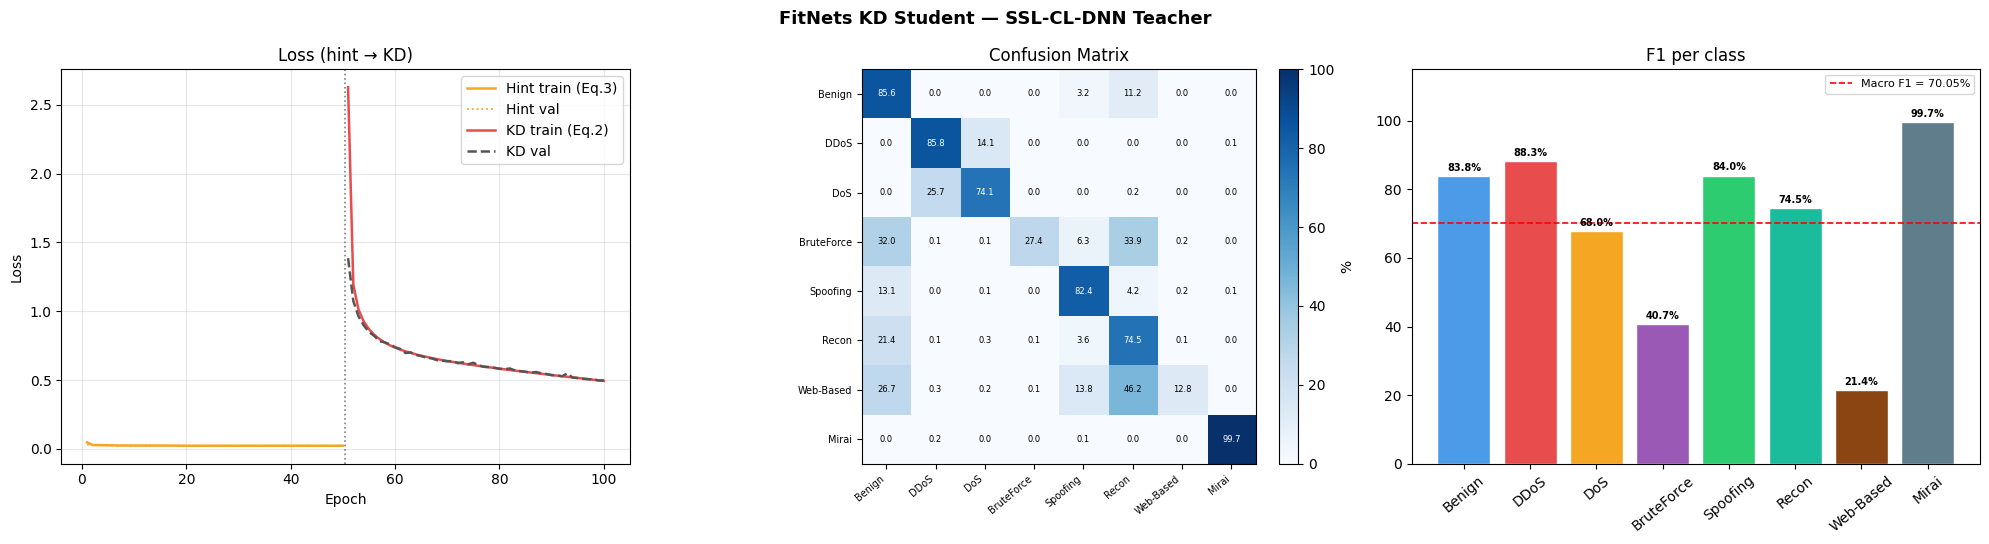

✓ Plot → /kaggle/working/fitnets_results.png


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
fig.suptitle('FitNets KD Student — SSL-CL-DNN Teacher', fontsize=13, fontweight='bold')

# (0) Loss curves: hint stage + KD stage
ax = axes[0]
if hint_losses:
    ep_h = range(1, len(hint_losses) + 1)
    ax.plot(ep_h, hint_losses, color='#F5A623', lw=1.8, label='Hint train (Eq.3)')
    if hint_val_losses:
        ax.plot(ep_h, hint_val_losses, color='#F5A623', lw=1.3, ls=':', label='Hint val')
if train_losses:
    ep_k = range(HINT_EPOCHS + 1, HINT_EPOCHS + len(train_losses) + 1)
    ax.plot(ep_k, train_losses, color='#E84C4C', lw=1.8, label='KD train (Eq.2)')
    ax.plot(ep_k, val_losses,   color='#555555', lw=1.8, ls='--', label='KD val')
ax.axvline(HINT_EPOCHS + 0.5, color='gray', ls=':', lw=1.2)
ax.set_title('Loss (hint → KD)'); ax.set_xlabel('Epoch'); ax.set_ylabel('Loss')
ax.legend(); ax.grid(alpha=0.3)

# (1) Confusion matrix (%)
ax = axes[1]
cm = confusion_matrix(labels, preds)
cm_pct = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100
im = ax.imshow(cm_pct, cmap='Blues', vmin=0, vmax=100)
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label='%')
ax.set_xticks(range(NUM_CLASSES)); ax.set_yticks(range(NUM_CLASSES))
ax.set_xticklabels(CLASS_NAMES, rotation=40, ha='right', fontsize=7)
ax.set_yticklabels(CLASS_NAMES, fontsize=7)
ax.set_title('Confusion Matrix')
thresh = cm_pct.max() / 2
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        v = cm_pct[i, j]
        ax.text(j, i, f'{v:.1f}', ha='center', va='center',
                fontsize=6, color='white' if v > thresh else 'black')

# (2) F1 per class
ax = axes[2]
f1s = f1_score(labels, preds, average=None, zero_division=0)
bars = ax.bar(CLASS_NAMES, f1s*100, color=COLORS, edgecolor='white')
ax.set_ylim(0, 115); ax.set_title('F1 per class')
ax.tick_params(axis='x', rotation=40)
ax.axhline(np.mean(f1s)*100, color='red', ls='--', lw=1.2,
           label=f'Macro F1 = {np.mean(f1s)*100:.2f}%')
ax.legend(fontsize=8)
for bar, val in zip(bars, f1s):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+1.5,
            f'{val*100:.1f}%', ha='center', fontsize=7, fontweight='bold')

plt.tight_layout()
plot_path = os.path.join(OUTPUT_DIR, 'fitnets_results.png')
plt.savefig(plot_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'✓ Plot → {plot_path}')


## Cell 10 — Export config & ONNX

In [11]:
class StudentInferenceOnly(nn.Module):
    """encoder + classifier (bỏ regressor)."""
    def __init__(self, enc, cls):
        super().__init__()
        self.encoder = enc
        self.classifier = cls
    def forward(self, x): return self.classifier(self.encoder(x))


def export_config_onnx(student, acc, macro_auc):
    n_params = count_params(student)
    config = {
        'model'        : 'FitNets-Student-MiniDNN',
        'teacher'      : 'SSL-CL-DNN',
        'num_features' : NUM_FEATURES,
        'num_classes'  : NUM_CLASSES,
        'distillation' : {
            'method'      : 'FitNets (Romero et al. 2015)',
            'stages'      : {'hint_epochs': HINT_EPOCHS, 'kd_epochs': KD_EPOCHS},
            'hint_dim'    : HINT_DIM,
            'guided_dim'  : GUIDED_DIM,
            'lambda_init' : LAMBDA_INIT, 'lambda_final': LAMBDA_FINAL,
            'tau'         : TAU,
        },
        'performance'  : {
            'accuracy'    : round(float(acc), 6),
            'macro_auc'   : round(float(macro_auc), 6),
            'params'      : n_params,
            'size_mb_fp32': round(n_params*4/1024**2, 4),
            'compression' : round(1 - n_params/t_params, 4),
        },
    }
    cfg_path = os.path.join(OUTPUT_DIR, 'config_fitnets.json')
    with open(cfg_path, 'w') as f: json.dump(config, f, indent=2)
    print(f'✓ Config → {cfg_path}')

    infer = StudentInferenceOnly(student.encoder.cpu().eval(),
                                 student.classifier.cpu().eval())
    try:
        onnx_path = os.path.join(OUTPUT_DIR, 'student_ssl_cl_dnn_fitnets.onnx')
        torch.onnx.export(
            infer, torch.randn(1, NUM_FEATURES), onnx_path,
            input_names=['features'], output_names=['logits'],
            dynamic_axes={'features':{0:'batch'},'logits':{0:'batch'}},
            opset_version=13,
        )
        sz = os.path.getsize(onnx_path)/1024
        print(f'✓ ONNX  → {onnx_path}  ({sz:.1f} KB)')
    except Exception as e:
        print(f'  ONNX ERROR: {e}')
    student.to(DEVICE)


export_config_onnx(student, acc, macro_auc)

print('\n' + '='*62)
print('  KẾT QUẢ FitNets Student')
print('='*62)
print(f'  {"Accuracy":20s}: {acc*100:.4f}%')
print(f'  {"Macro AUC":20s}: {macro_auc:.6f}')
print(f'  {"Params":20s}: {count_params(student):,}')
print(f'  {"Size (MB)":20s}: {count_params(student)*4/1024**2:.4f}')
print(f'  {"Compression":20s}: {1 - count_params(student)/t_params:.1%}')
print('='*62)
print('\nOutput files:')
for fname in sorted(os.listdir(OUTPUT_DIR)):
    fp = os.path.join(OUTPUT_DIR, fname)
    if os.path.isfile(fp):
        print(f'  {fname:<45} {os.path.getsize(fp)/1024:>8.1f} KB')


✓ Config → /kaggle/working/config_fitnets.json
  ONNX ERROR: No module named 'onnxscript'

  KẾT QUẢ FitNets Student
  Accuracy            : 84.3807%
  Macro AUC           : 0.978170
  Params              : 19,624
  Size (MB)           : 0.0749
  Compression         : 96.4%

Output files:
  __notebook__.ipynb                               207.2 KB
  config_fitnets.json                                0.5 KB
  fitnets_results.png                              162.4 KB
  results_fitnets.txt                                1.5 KB
  student_ssl_cl_dnn_fitnets_37ft.pth               81.5 KB
